# Exploratory data analysis: `application_train`

Main table only.

1. Load and overview
2. Column profile: every column in one table
3. Distributions of single columns
4. Target
5. Missing values
6. Anomalies
7. Categorical and near-constant columns
8. Relationship to the target
9. Domain features
10. Summary: preprocessing decisions

Imports and the path to the raw data (relative to this notebook).

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/raw")
pd.set_option("display.max_columns", 50)

## 1. Load and overview

Load both files and compare their size (rows, columns).

In [11]:
train = pd.read_csv(DATA / "application_train.csv")
test = pd.read_csv(DATA / "application_test.csv")
train.shape, test.shape

((307511, 122), (48744, 121))

First five rows: one row per application. `SK_ID_CURR` is the client ID, `TARGET` the label.

In [12]:
train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Sanity checks: are client IDs unique, do train and test overlap, which column exists only in train?

In [13]:
print("duplicate IDs:", train["SK_ID_CURR"].duplicated().sum())
print("IDs in both train and test:", len(set(train["SK_ID_CURR"]) & set(test["SK_ID_CURR"])))
print("columns only in train:", set(train.columns) - set(test.columns))

duplicate IDs: 0
IDs in both train and test: 0
columns only in train: {'TARGET'}


**Findings**
- 307,511 applications × 122 columns. Test: 48,744 × 121 (no `TARGET`).
- `SK_ID_CURR` is unique, and no client appears in both train and test.

## 2. Column profile

Kaggle's data dictionary: one description per column of this table.

In [14]:
dictionary = pd.read_csv(DATA / "HomeCredit_columns_description.csv", encoding="latin-1")
descriptions = dictionary[dictionary["Table"] == "application_{train|test}.csv"].set_index("Row")["Description"]
len(descriptions)

122

Group the columns by meaning, mostly by their name prefix. Every column gets exactly one group.

In [38]:
LOAN = ["NAME_CONTRACT_TYPE", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
APPLICANT = ["CODE_GENDER", "DAYS_BIRTH", "NAME_FAMILY_STATUS", "CNT_CHILDREN", "CNT_FAM_MEMBERS",
             "NAME_EDUCATION_TYPE", "NAME_TYPE_SUITE", "FLAG_OWN_CAR", "OWN_CAR_AGE", "FLAG_OWN_REALTY"]
EMPLOYMENT = ["AMT_INCOME_TOTAL", "NAME_INCOME_TYPE", "DAYS_EMPLOYED", "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]
PROCESS = ["WEEKDAY_APPR_PROCESS_START", "HOUR_APPR_PROCESS_START", "DAYS_REGISTRATION",
           "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE"]
CONTACT = ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE", "FLAG_CONT_MOBILE", "FLAG_PHONE", "FLAG_EMAIL"]

GROUPS = ["ID / target", "Loan", "Applicant", "Employment & income", "External scores", "Region & address",
          "Building", "Application process", "Contact flags", "Documents", "Social circle",
          "Credit bureau inquiries"]


def column_group(col):
    if col in ("SK_ID_CURR", "TARGET"):
        return "ID / target"
    if col in LOAN:
        return "Loan"
    if col in APPLICANT:
        return "Applicant"
    if col in EMPLOYMENT:
        return "Employment & income"
    if col.startswith("EXT_SOURCE_"):
        return "External scores"
    if col.startswith(("REGION_", "REG_", "LIVE_")) or col == "NAME_HOUSING_TYPE":
        return "Region & address"
    if col.endswith(("_AVG", "_MODE", "_MEDI")):
        return "Building"
    if col in PROCESS:
        return "Application process"
    if col in CONTACT:
        return "Contact flags"
    if col.startswith("FLAG_DOCUMENT_"):
        return "Documents"
    if "SOCIAL_CIRCLE" in col:
        return "Social circle"
    if col.startswith("AMT_REQ_CREDIT_BUREAU_"):
        return "Credit bureau inquiries"
    raise ValueError(f"no group for {col}")

**The profile:** one row per column, sorted by group. For numeric columns: min, median, mean, max.
For every column: share missing, number of distinct values, and the most frequent value with its share.

In [16]:
def profile_column(s):
    numeric = pd.api.types.is_numeric_dtype(s)
    counts = s.value_counts(normalize=True)
    return {
        "group": column_group(s.name),
        "dtype": str(s.dtype),
        "missing %": round(100 * s.isna().mean(), 1),
        "unique": s.nunique(),
        "min": s.min() if numeric else None,
        "median": s.median() if numeric else None,
        "mean": round(s.mean(), 2) if numeric else None,
        "max": s.max() if numeric else None,
        "most frequent": counts.index[0],
        "top %": round(100 * counts.iloc[0], 1),
        "description": descriptions[s.name],
    }


profile = pd.DataFrame([profile_column(train[c]) for c in train.columns], index=train.columns)
profile["group"] = pd.Categorical(profile["group"], categories=GROUPS, ordered=True)
profile = profile.sort_values("group", kind="stable")

with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
    display(profile)

,group,dtype,missing %,unique,min,median,mean,max,most frequent,top %,description
SK_ID_CURR,ID / target,int64,0.0,307511,1.000020e+05,278202.000000,278180.52,4.562550e+05,456255,0.0,ID of loan in our sample
TARGET,ID / target,int64,0.0,2,0.000000e+00,0.000000,0.08,1.000000e+00,0,91.9,Target variable (1 - client with payment difficulties: he/she had ...
NAME_CONTRACT_TYPE,Loan,object,0.0,2,NaN,NaN,NaN,NaN,Cash loans,90.5,Identification if loan is cash or revolving
AMT_CREDIT,Loan,float64,0.0,5603,4.500000e+04,513531.000000,599026.00,4.050000e+06,450000.0,3.2,Credit amount of the loan
AMT_ANNUITY,Loan,float64,0.0,13672,1.615500e+03,24903.000000,27108.57,2.580255e+05,9000.0,2.1,Loan annuity
AMT_GOODS_PRICE,Loan,float64,0.1,1002,4.050000e+04,450000.000000,538396.21,4.050000e+06,450000.0,8.5,For consumer loans it is the price of the goods for which the loan...
CODE_GENDER,Applicant,object,0.0,3,NaN,NaN,NaN,NaN,F,65.8,Gender of the client
FLAG_OWN_CAR,Applicant,object,0.0,2,NaN,NaN,NaN,NaN,N,66.0,Flag if the client owns a car
FLAG_OWN_REALTY,Applicant,object,0.0,2,NaN,NaN,NaN,NaN,Y,69.4,Flag if client owns a house or flat
CNT_CHILDREN,Applicant,int64,0.0,15,0.000000e+00,0.000000,0.42,1.900000e+01,0,70.0,Number of children the client has


Size of each group: number of columns, how many are text, and the average share missing.

In [17]:
profile.groupby("group", observed=True).agg(
    columns=("dtype", "size"),
    text_columns=("dtype", lambda d: (d == "object").sum()),
    mean_missing_pct=("missing %", "mean"),
).round(1)

,columns,text_columns,mean_missing_pct
group,,,
ID / target,2,0,0.0
Loan,4,1,0.0
Applicant,10,6,6.6
Employment & income,5,3,6.3
External scores,3,0,25.5
Region & address,10,1,0.0
Building,47,4,57.9
Application process,5,1,0.0
Contact flags,6,0,0.0


**What stands out when reading the profile** (details in sections 4–7)
- **Groups:** 122 columns in 12 groups. The building block alone has 47 columns, the documents 20.
- **`SK_ID_CURR`** has a different value in every row: an identifier, not a feature.
- **`DAYS_*` columns are negative:** days before the application. `DAYS_BIRTH` −25,229 to −7,489 means ages of 20.5 to 69.1 years.
- **`DAYS_EMPLOYED`:** maximum 365,243 days (≈ 1,000 years), and it is the *most frequent* value (18%). That is a placeholder, not a real duration (section 6).
- **`AMT_INCOME_TOTAL`:** maximum 117,000,000 against a median of 147,150.
- **`OWN_CAR_AGE`:** cars up to 91 years old (section 6).
- **`DAYS_LAST_PHONE_CHANGE`:** 0 ("changed the phone on the day of the application") is the most frequent value, 12.3%.
- **Single extreme values:** `OBS_30_CNT_SOCIAL_CIRCLE` up to 348 (mean 1.4), `AMT_REQ_CREDIT_BUREAU_QRT` up to 261 (mean 0.3), `CNT_CHILDREN` up to 19.
- **Almost constant:** `FLAG_MOBIL` (top value 100%), `FLAG_CONT_MOBILE` (99.8%), several `FLAG_DOCUMENT_*` (section 7).
- **`CODE_GENDER`** has 3 distinct values instead of 2 (section 6).
- **Already scaled to 0–1:** the building columns and the `EXT_SOURCE_*` scores.
- **Ordinal numbers:** `REGION_RATING_CLIENT*` take only the values 1, 2 and 3. They are ratings, not amounts.

## 3. Distributions of single columns

Histogram of every numeric column that is not just 0/1, outside the building block. Raw values, 50 bins.

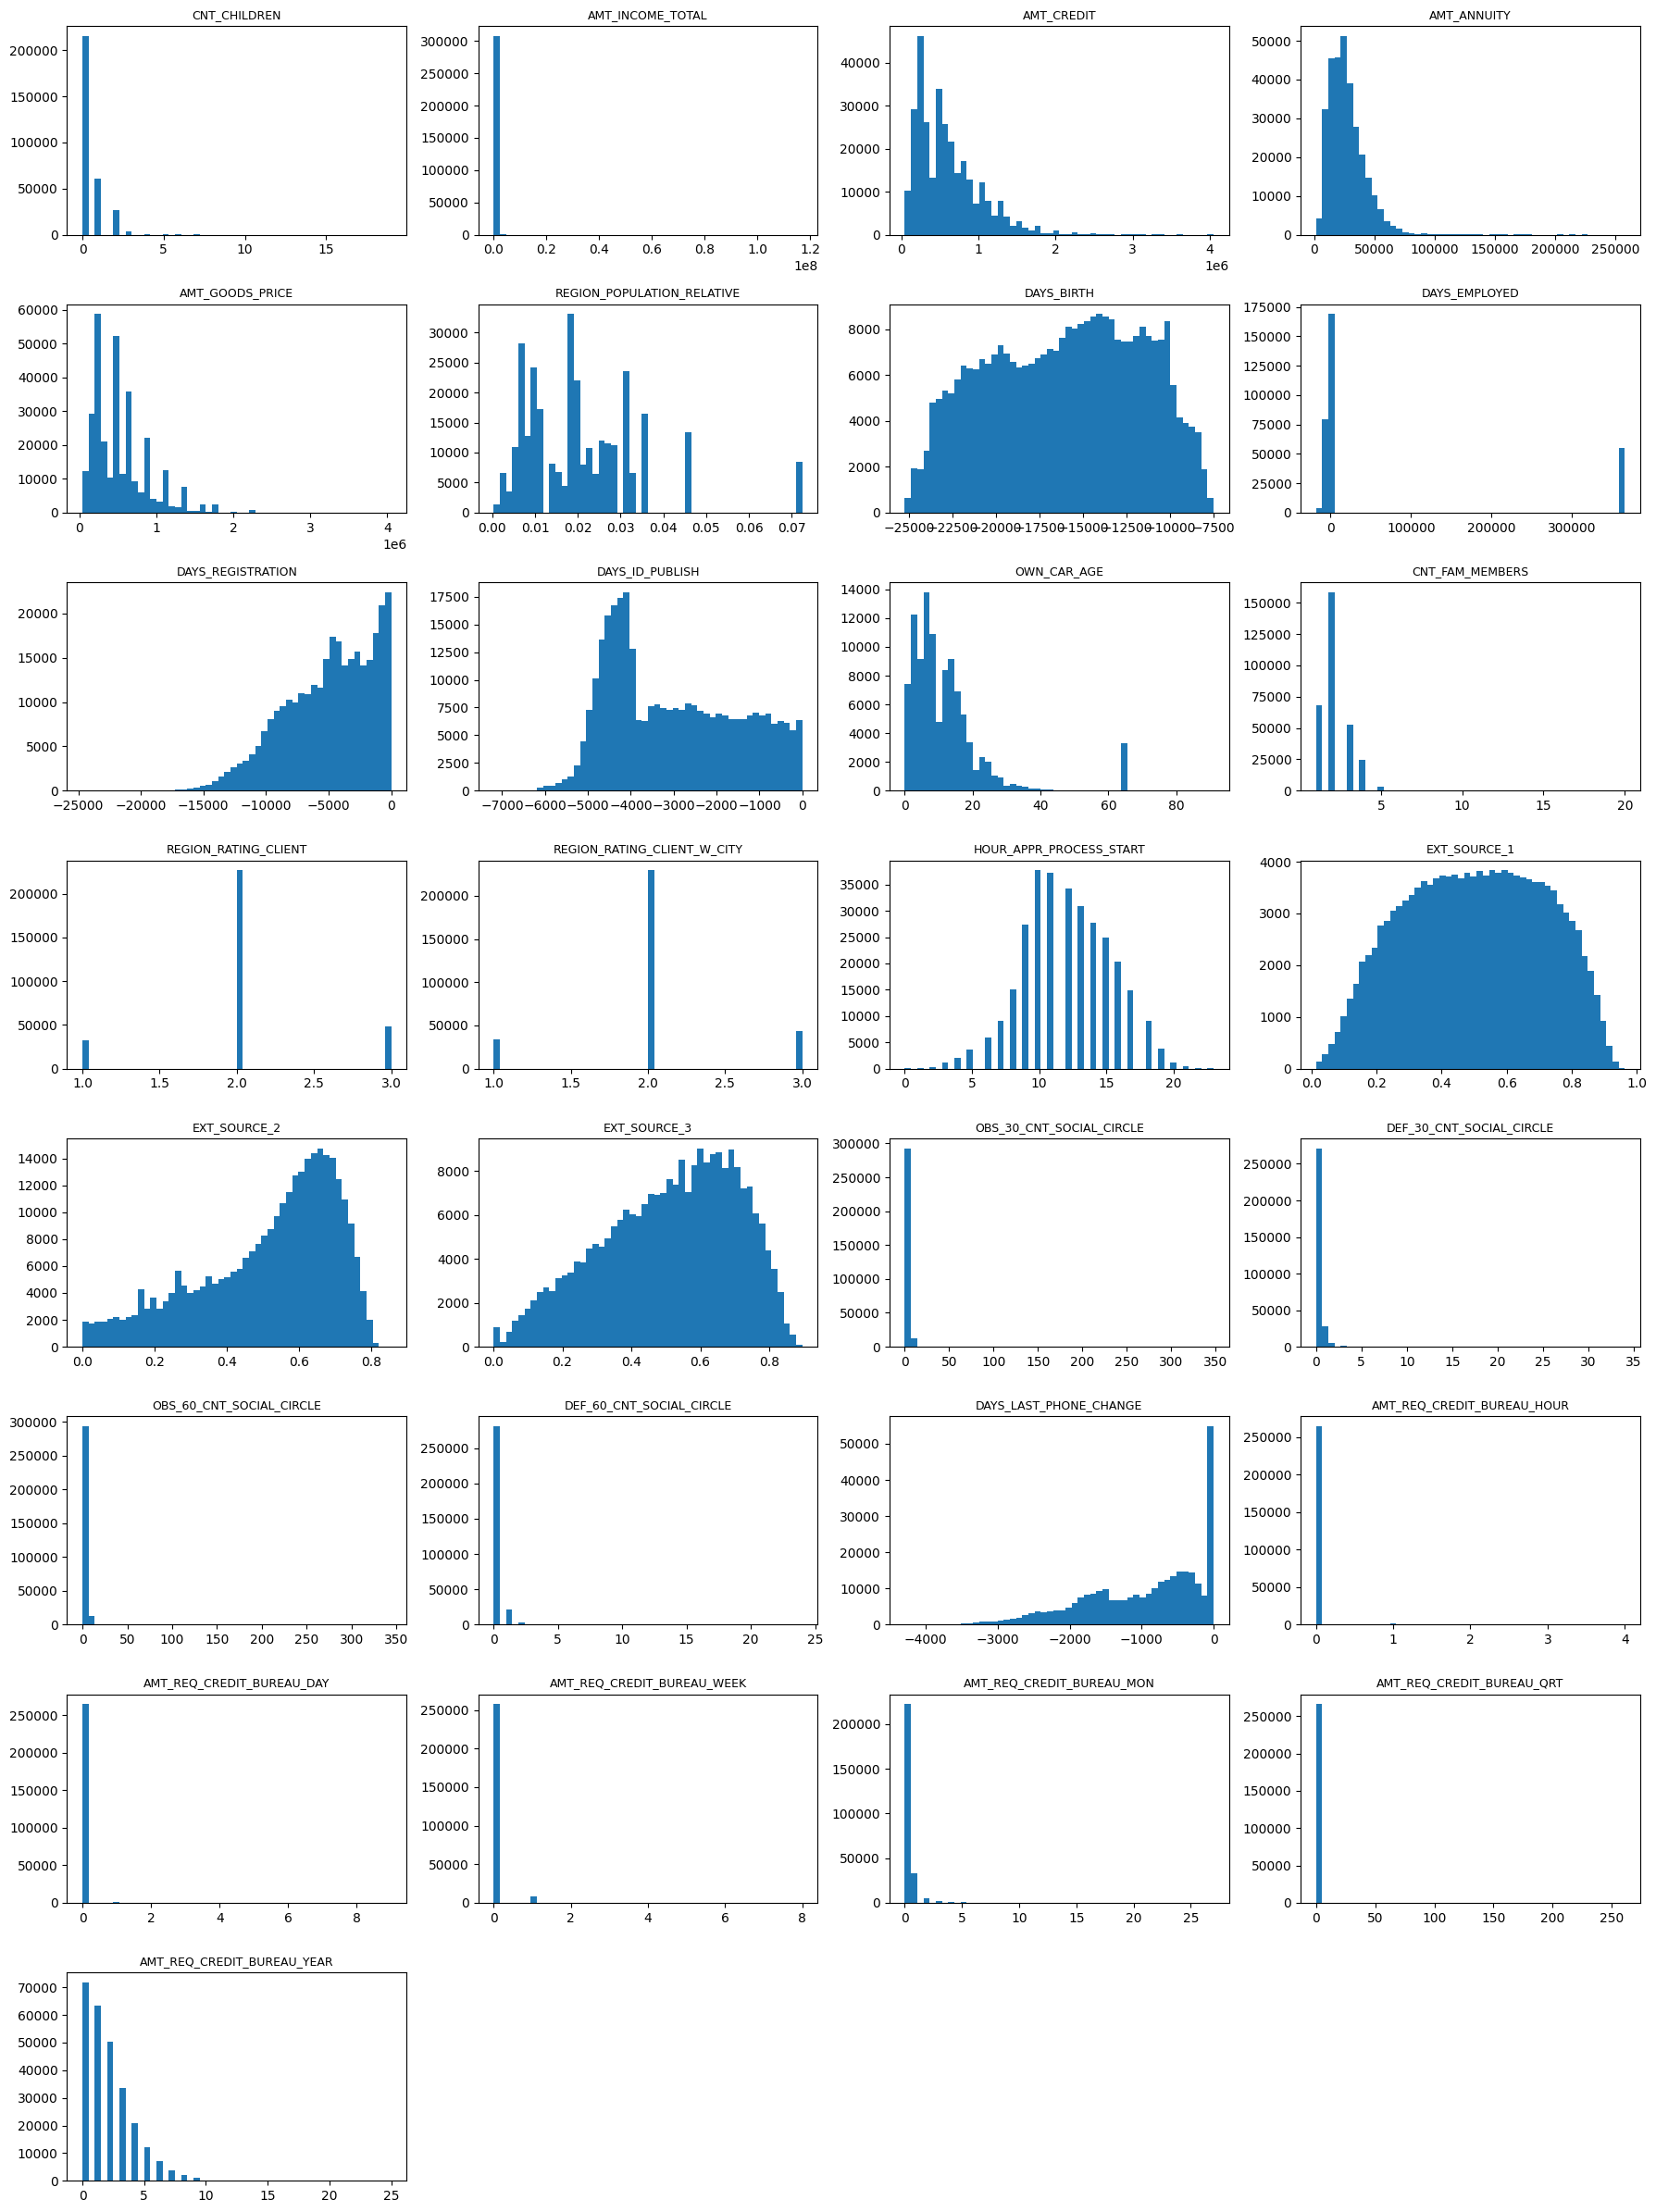

In [18]:
numeric_cols = [c for c in train.select_dtypes("number").columns
                if c not in ("SK_ID_CURR", "TARGET") and train[c].nunique() > 2
                and profile.loc[c, "group"] != "Building"]

ncols = 4
nrows = -(-len(numeric_cols) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3 * nrows))
for ax, col in zip(axes.flat, numeric_cols):
    ax.hist(train[col].dropna(), bins=50)
    ax.set_title(col, fontsize=9)
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
plt.tight_layout()
plt.show()

The 10 most frequent values of every text column, missing values shown as `NaN`.

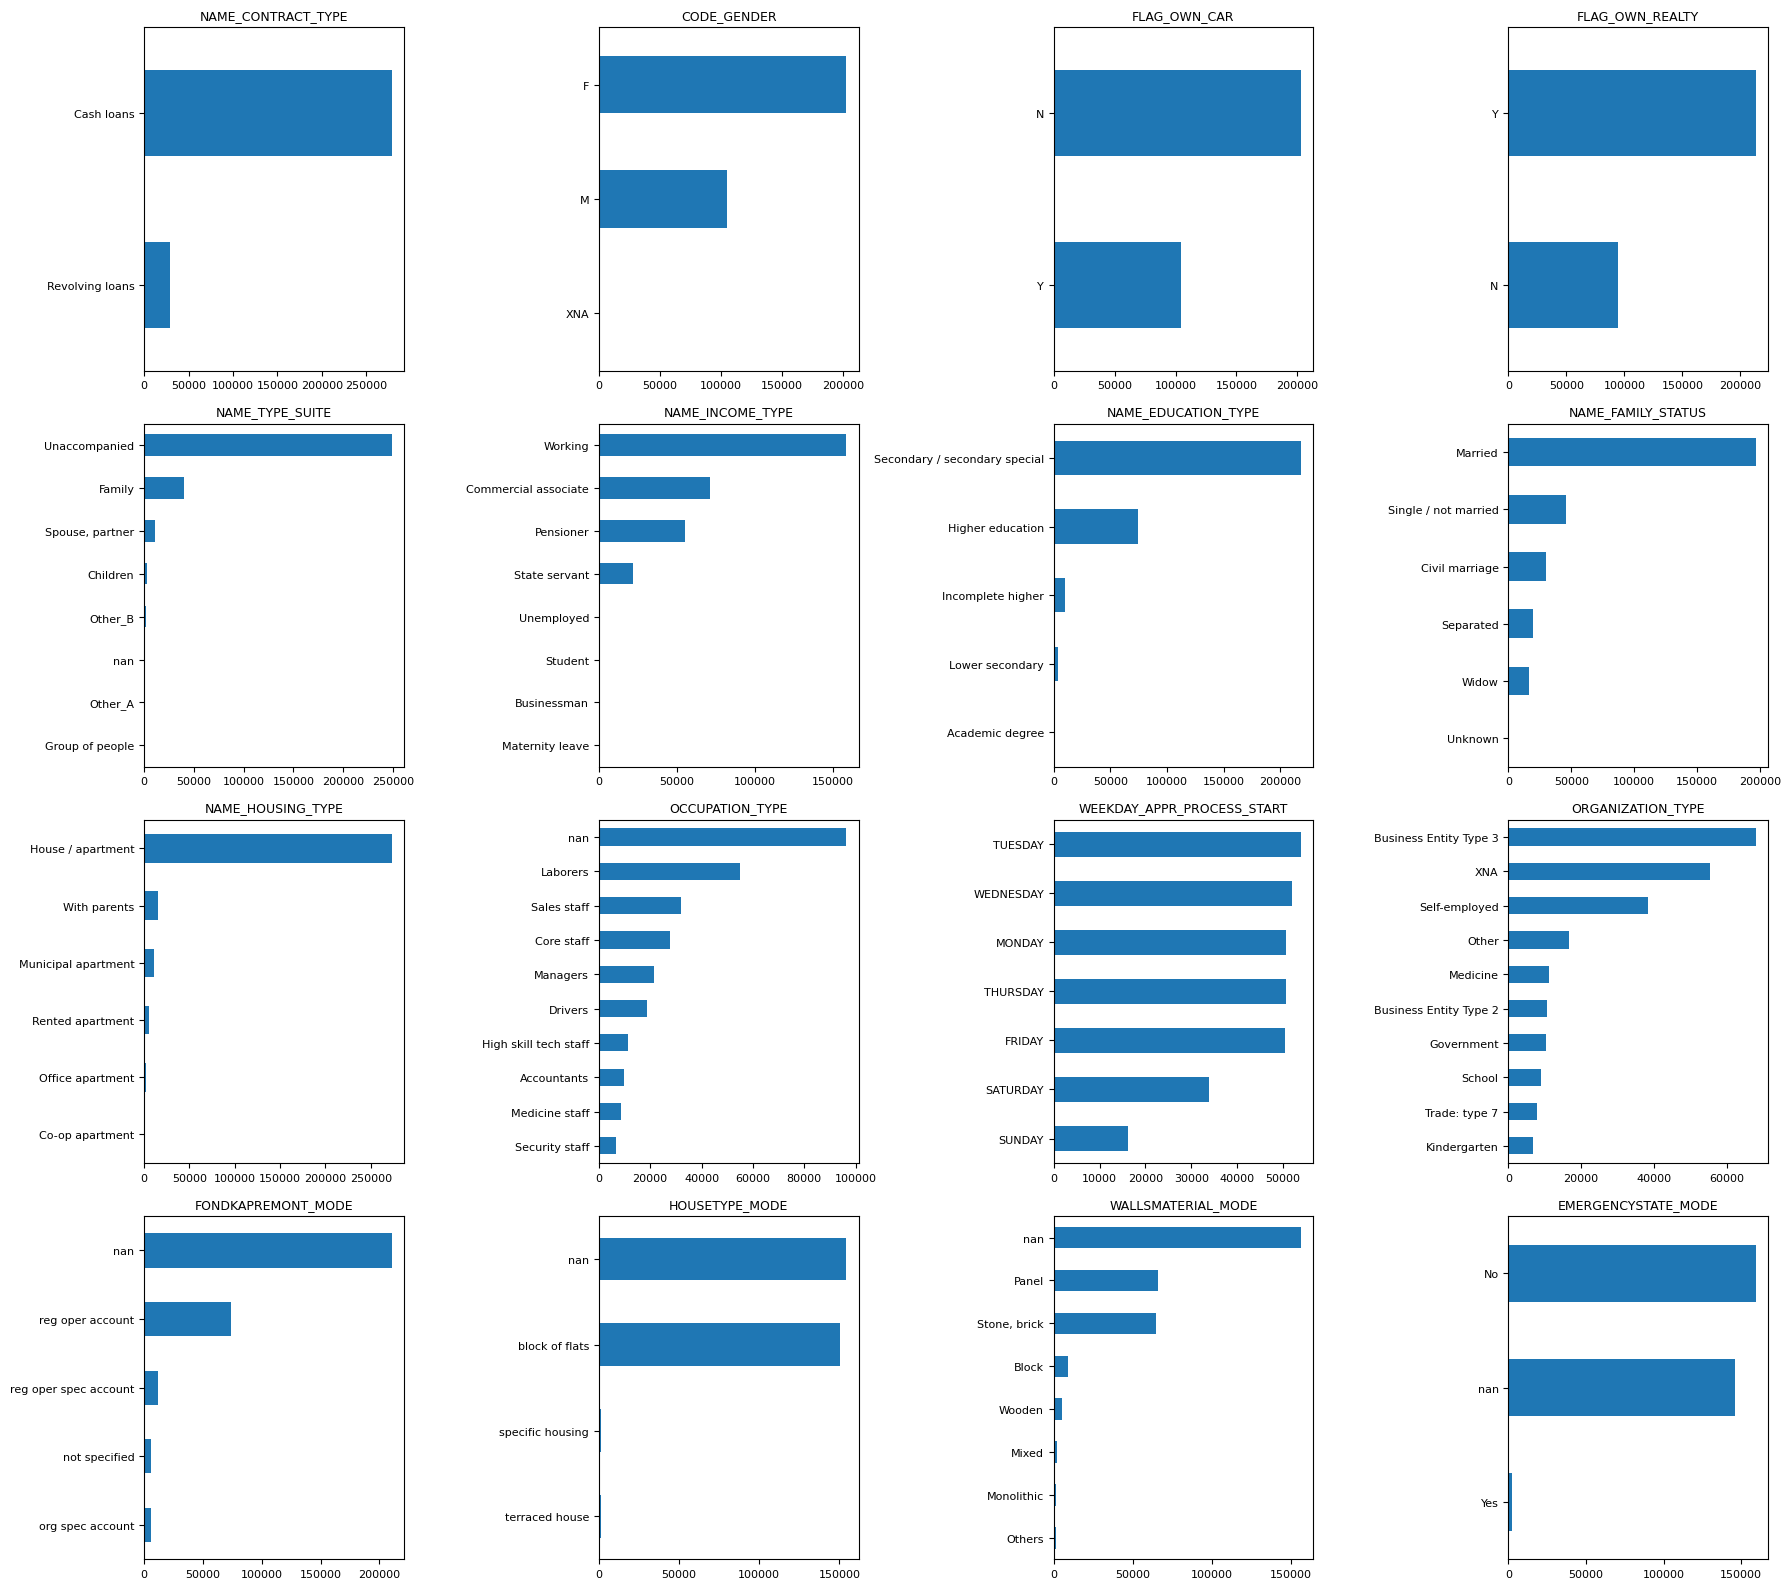

In [19]:
text_cols = train.select_dtypes(exclude="number").columns
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, col in zip(axes.flat, text_cols):
    train[col].value_counts(dropna=False).head(10).sort_values().plot.barh(ax=ax, fontsize=8)
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Findings**
- Where a column has an extreme value, its histogram collapses into a single bar: `AMT_INCOME_TOTAL`, `DAYS_EMPLOYED` (the 365,243 spike), `OBS_*`/`DEF_*_CNT_SOCIAL_CIRCLE`, `AMT_REQ_CREDIT_BUREAU_QRT`.
- The money amounts (`AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`) are right-skewed: many small loans, few large ones. `AMT_GOODS_PRICE` has spikes at round prices.
- Two isolated spikes: `OWN_CAR_AGE` around 64–65 years, far right of the bulk; `DAYS_LAST_PHONE_CHANGE` at exactly 0.
- `EXT_SOURCE_2` and `EXT_SOURCE_3` lean towards high scores; `EXT_SOURCE_1` is more symmetric.
- Text columns: "missing" (`NaN`) is the *largest* category of `OCCUPATION_TYPE` and of the building columns `FONDKAPREMONT_MODE`, `HOUSETYPE_MODE`, `WALLSMATERIAL_MODE`. `ORGANIZATION_TYPE` has a large `XNA` category. Fewer applications on weekends.

## 4. Target

Class balance: share of repaid (0) vs. default (1).

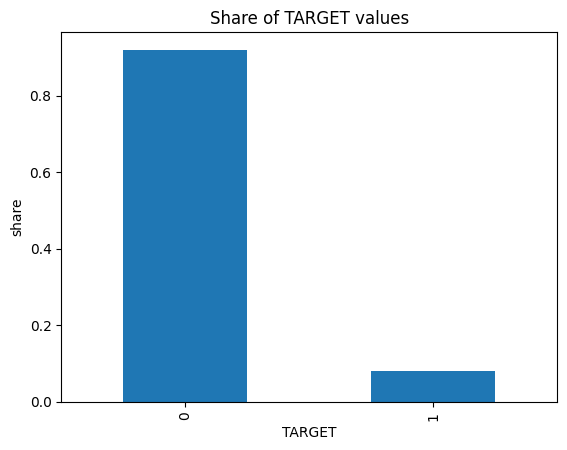

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

In [20]:
target_share = train["TARGET"].value_counts(normalize=True)
target_share.plot.bar(title="Share of TARGET values", ylabel="share")
plt.show()
target_share

**Findings**
- 8.1% defaults (`TARGET = 1`), 91.9% repaid. Always predicting "repays" gives 91.9% accuracy, so accuracy alone is misleading.
- **Decision:** ROC-AUC (primary) and PR-AUC; stratified train/test split and CV folds so every part keeps 8.1% defaults.

## 5. Missing values

Share of missing values per column, sorted. The plot shows only columns with at least one missing value.

columns with missing values: 67
columns with > 50% missing: 41


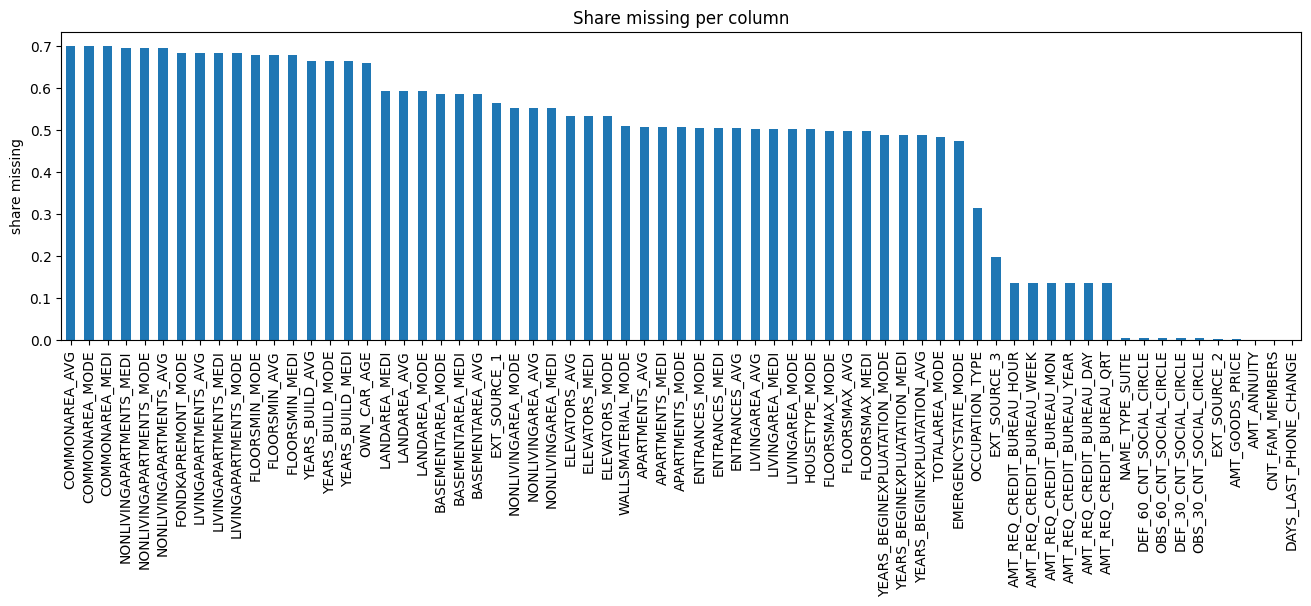

In [21]:
missing = train.isna().mean().sort_values(ascending=False)
print("columns with missing values:", (missing > 0).sum())
print("columns with > 50% missing:", (missing > 0.5).sum())
missing[missing > 0].plot.bar(figsize=(16, 4), title="Share missing per column", ylabel="share missing")
plt.show()

Most of these columns are the building block, where each measure comes in three versions
(`_AVG` mean, `_MODE` most frequent value, `_MEDI` median).
How often is the whole block missing, and how similar are the three versions (correlation)?

In [22]:
building = profile.index[profile["group"] == "Building"]
print("building columns:", len(building))
print("rows missing all of them:", round(train[building].isna().all(axis=1).mean(), 3))
train[["APARTMENTS_AVG", "APARTMENTS_MEDI", "APARTMENTS_MODE"]].corr().round(3)

building columns: 47
rows missing all of them: 0.474


,APARTMENTS_AVG,APARTMENTS_MEDI,APARTMENTS_MODE
APARTMENTS_AVG,1.000,0.995,0.973
APARTMENTS_MEDI,0.995,1.000,0.977
APARTMENTS_MODE,0.973,0.977,1.000


Is missingness informative? Default rate of clients whose value is present vs. missing,
for four heavily missing columns. `TARGET` is 0/1, so its mean is the default rate.

In [23]:
cols = ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "OCCUPATION_TYPE"]
default_rate = {c: train.groupby(train[c].isna())["TARGET"].mean() for c in cols}
pd.DataFrame(default_rate).T.rename(columns={False: "value present", True: "value missing"}).round(3)

,value present,value missing
EXT_SOURCE_1,0.075,0.085
EXT_SOURCE_3,0.078,0.093
OWN_CAR_AGE,0.072,0.085
OCCUPATION_TYPE,0.088,0.065


Why do clients without an occupation default *less*? Share of pensioners among them.

In [24]:
no_occupation = train["OCCUPATION_TYPE"].isna()
pensioner = train["NAME_INCOME_TYPE"] == "Pensioner"
print("pensioners among clients without occupation:", round(pensioner[no_occupation].mean(), 3))
print("default rate, no occupation and not a pensioner:", round(train.loc[no_occupation & ~pensioner, "TARGET"].mean(), 3))

pensioners among clients without occupation: 0.574
default rate, no occupation and not a pensioner: 0.08


**Findings**
- 67 columns have missing values, 41 of them more than 50%.
- 47 of these are the building block. 47% of rows have none of its values. The three versions of a measure are almost identical (r ≈ 0.97–0.99), so the block is largely redundant.
- `EXT_SOURCE_1` is 56% missing but is one of the strongest features (section 8): dropping columns with > 50% missing would throw it away.
- Missingness itself predicts default: 9.3% default rate when `EXT_SOURCE_3` is missing vs 7.8% when present.
- Missing `OCCUPATION_TYPE` means lower risk only because 57% of these clients are pensioners. Without the pensioners, their default rate is 8.0%, close to the average.
- **Decision:** keep all rows; impute and add a missing-indicator column (`SimpleImputer(add_indicator=True)`), fitted on training data only.

## 6. Anomalies

`DAYS_EMPLOYED = 365243`: who are these clients, and do they default differently?

In [25]:
employed_anomaly = train["DAYS_EMPLOYED"] == 365243
print("rows with DAYS_EMPLOYED = 365243:", employed_anomaly.sum(), f"({employed_anomaly.mean():.1%})")
print("same in test:", (test["DAYS_EMPLOYED"] == 365243).sum())
print("ORGANIZATION_TYPE is 'XNA' on exactly these rows:",
      ((train["ORGANIZATION_TYPE"] == "XNA") == employed_anomaly).all())
print(train.loc[employed_anomaly, "NAME_INCOME_TYPE"].value_counts().to_dict())
train.groupby(employed_anomaly)["TARGET"].mean().rename({False: "other", True: "365243"}).round(3)

rows with DAYS_EMPLOYED = 365243: 55374 (18.0%)
same in test: 9274
ORGANIZATION_TYPE is 'XNA' on exactly these rows: True
{'Pensioner': 55352, 'Unemployed': 22}


DAYS_EMPLOYED
other     0.087
365243    0.054
Name: TARGET, dtype: float64

Employment length in years once the placeholder is removed: now a normal-looking distribution.

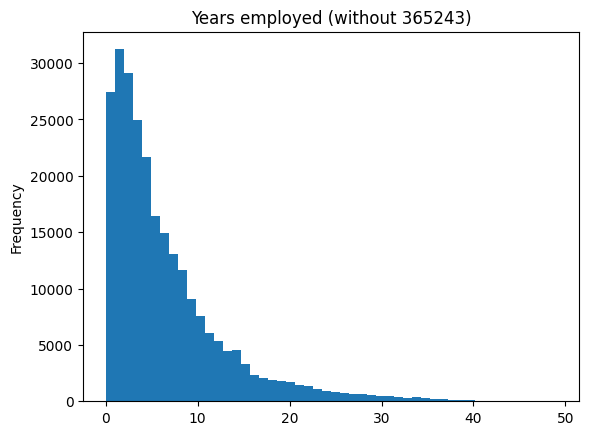

In [26]:
years_employed = -train.loc[~employed_anomaly, "DAYS_EMPLOYED"] / 365.25
years_employed.plot.hist(bins=50, title="Years employed (without 365243)")
plt.show()

`OWN_CAR_AGE`: the most frequent ages at the top end.

In [27]:
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"].value_counts()

OWN_CAR_AGE
64.0    2443
65.0     891
63.0       2
91.0       2
69.0       1
Name: count, dtype: int64

`DAYS_LAST_PHONE_CHANGE = 0`: how common, and do these clients default differently?

In [28]:
phone_today = train["DAYS_LAST_PHONE_CHANGE"] == 0
print("rows:", phone_today.sum(), f"({phone_today.mean():.1%})")
train.groupby(phone_today)["TARGET"].mean().rename({False: "other", True: "0"}).round(3)

rows: 37672 (12.3%)


DAYS_LAST_PHONE_CHANGE
other    0.079
0        0.097
Name: TARGET, dtype: float64

Placeholder categories (`XNA`, `Unknown`) and the extreme values found in the profile.

In [29]:
print("CODE_GENDER:", train["CODE_GENDER"].value_counts().to_dict(), "| test:", test["CODE_GENDER"].value_counts().to_dict())
print("NAME_FAMILY_STATUS 'Unknown':", (train["NAME_FAMILY_STATUS"] == "Unknown").sum())
print("FLAG_MOBIL = 0:", (train["FLAG_MOBIL"] == 0).sum())
print("income > 10,000,000:", (train["AMT_INCOME_TOTAL"] > 1e7).sum())
print("OBS_30_CNT_SOCIAL_CIRCLE > 50:", (train["OBS_30_CNT_SOCIAL_CIRCLE"] > 50).sum())
print("AMT_REQ_CREDIT_BUREAU_QRT > 30:", (train["AMT_REQ_CREDIT_BUREAU_QRT"] > 30).sum())
print("CNT_CHILDREN >= 6:", (train["CNT_CHILDREN"] >= 6).sum())

CODE_GENDER: {'F': 202448, 'M': 105059, 'XNA': 4} | test: {'F': 32678, 'M': 16066}
NAME_FAMILY_STATUS 'Unknown': 2
FLAG_MOBIL = 0: 1
income > 10,000,000: 3
OBS_30_CNT_SOCIAL_CIRCLE > 50: 1
AMT_REQ_CREDIT_BUREAU_QRT > 30: 1
CNT_CHILDREN >= 6: 42


**Findings**
- `DAYS_EMPLOYED = 365243` on 55,374 rows (18%): 55,352 pensioners and 22 unemployed. `ORGANIZATION_TYPE = 'XNA'` on exactly the same rows. Also 9,274 rows in test. These clients default less (5.4% vs 8.7%).
- `OWN_CAR_AGE` is exactly 64 or 65 for 3,334 cars, a spike that looks like a placeholder rather than real car ages.
- `DAYS_LAST_PHONE_CHANGE = 0` for 37,672 clients (12.3%), more than any other day. It is unclear whether 0 means "today" or "unknown", but these clients default more often (9.7% vs 7.9%).
- `CODE_GENDER = 'XNA'` on 4 rows, `NAME_FAMILY_STATUS = 'Unknown'` on 2; neither occurs in test.
- Single extreme rows: 3 incomes above 10 million (max 117 million), 1 client with > 50 social-circle observations, 1 with > 30 bureau inquiries in a quarter. 42 clients have 6 or more children (rare but plausible).
- **Decision:**
  - `DAYS_EMPLOYED = 365243`: replace the number with an empty value (`NaN`), so it no longer counts as 1,000 years of work, and add a 0/1 column `NOT_EMPLOYED` that keeps the information "pensioner or unemployed".
  - `CODE_GENDER = 'XNA'` and `NAME_FAMILY_STATUS = 'Unknown'` (6 rows): replace with `NaN`, filled with the most frequent category.
  - `ORGANIZATION_TYPE = 'XNA'`: keep as its own category. It means "no employer" (the same rows as `NOT_EMPLOYED`).
  - Money amounts: log-transform for LR and MLP, so single extreme incomes don't dominate the scaling.
  - `OWN_CAR_AGE` 64/65 and `DAYS_LAST_PHONE_CHANGE = 0`: keep unchanged.

## 7. Categorical and near-constant columns

Number of distinct categories per text column. This decides how many columns one-hot encoding creates.

In [30]:
text_cols = train.select_dtypes(exclude="number").columns
train[text_cols].nunique().sort_values()

NAME_CONTRACT_TYPE             2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
HOUSETYPE_MODE                 3
CODE_GENDER                    3
FONDKAPREMONT_MODE             4
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
WEEKDAY_APPR_PROCESS_START     7
NAME_TYPE_SUITE                7
WALLSMATERIAL_MODE             7
NAME_INCOME_TYPE               8
OCCUPATION_TYPE               18
ORGANIZATION_TYPE             58
dtype: int64

Category counts of a column with very rare categories.

In [31]:
train["NAME_INCOME_TYPE"].value_counts()

NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

Columns where one value covers more than 99.9% of rows carry almost no information.

In [32]:
near_constant = [c for c in train.columns if train[c].value_counts(normalize=True).iloc[0] > 0.999]
print(len(near_constant), "near-constant columns:", near_constant)

10 near-constant columns: ['FLAG_MOBIL', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_12', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21']


**Findings**
- 16 text columns, most with ≤ 8 categories; `OCCUPATION_TYPE` has 18, `ORGANIZATION_TYPE` 58. One-hot encoding turns them into about 140 columns.
- Rare categories: `NAME_INCOME_TYPE` has Unemployed (22), Student (18), Businessman (10), Maternity leave (5).
- 10 columns are > 99.9% one value: `FLAG_MOBIL` and 9 of the 20 document flags.
- **Decision:** one-hot for LR/MLP with rare categories (< 0.1%) grouped as "Other"; native categorical handling for gradient boosting (`HistGradientBoostingClassifier`). Drop the near-constant columns.

## 8. Relationship to the target

Linear (Pearson) correlation of each numeric column with `TARGET`: the 6 most negative and 6 most positive.

In [33]:
numeric = train.select_dtypes("number").drop(columns=["SK_ID_CURR", "TARGET"])
corr = numeric.corrwith(train["TARGET"]).sort_values()
pd.concat([corr.head(6), corr.tail(6)]).round(3)

EXT_SOURCE_3                  -0.179
EXT_SOURCE_2                  -0.160
EXT_SOURCE_1                  -0.155
DAYS_EMPLOYED                 -0.045
FLOORSMAX_AVG                 -0.044
FLOORSMAX_MEDI                -0.044
REG_CITY_NOT_WORK_CITY         0.051
DAYS_ID_PUBLISH                0.051
DAYS_LAST_PHONE_CHANGE         0.055
REGION_RATING_CLIENT           0.059
REGION_RATING_CLIENT_W_CITY    0.061
DAYS_BIRTH                     0.078
dtype: float64

Default rate per quintile (5 equally sized groups) of each external score,
and how strongly the three scores correlate with each other.

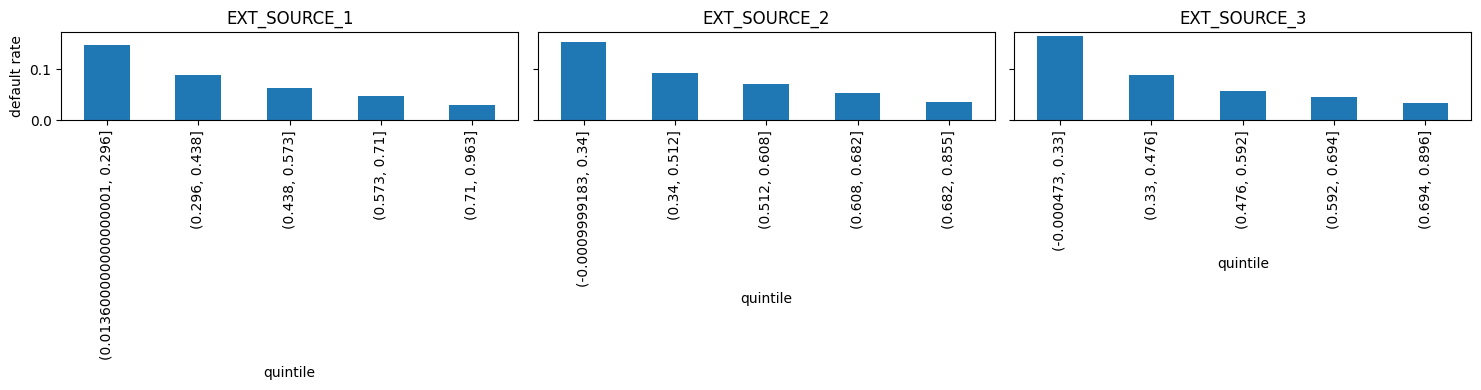

,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3
EXT_SOURCE_1,1.00,0.21,0.19
EXT_SOURCE_2,0.21,1.00,0.11
EXT_SOURCE_3,0.19,0.11,1.00


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    train.groupby(pd.qcut(train[col], 5), observed=True)["TARGET"].mean().plot.bar(ax=ax, title=col, xlabel="quintile")
axes[0].set_ylabel("default rate")
plt.tight_layout()
plt.show()
train[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].corr().round(2)

Default rate per age group.

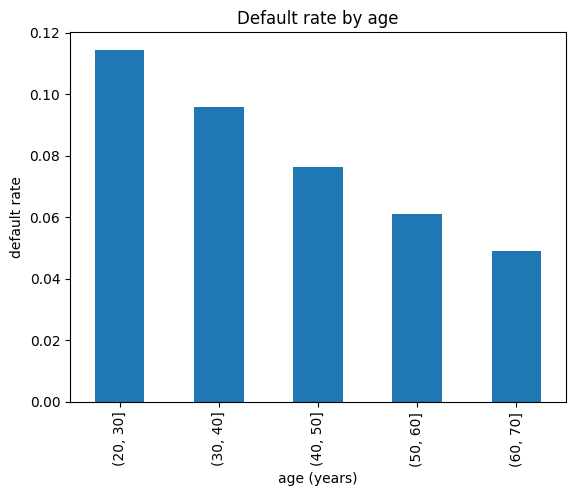

In [35]:
age = -train["DAYS_BIRTH"] / 365.25
train.groupby(pd.cut(age, [20, 30, 40, 50, 60, 70]), observed=True)["TARGET"].mean().plot.bar(
    title="Default rate by age", xlabel="age (years)", ylabel="default rate")
plt.show()

Default rate (`mean`) and number of clients (`size`) per category, for three categorical columns.

In [36]:
for col in ["NAME_EDUCATION_TYPE", "NAME_CONTRACT_TYPE", "CODE_GENDER"]:
    print(train.groupby(col)["TARGET"].agg(["mean", "size"]).round(3), "\n")

                                mean    size
NAME_EDUCATION_TYPE                         
Academic degree                0.018     164
Higher education               0.054   74863
Incomplete higher              0.085   10277
Lower secondary                0.109    3816
Secondary / secondary special  0.089  218391 

                     mean    size
NAME_CONTRACT_TYPE               
Cash loans          0.083  278232
Revolving loans     0.055   29279 

              mean    size
CODE_GENDER               
F            0.070  202448
M            0.101  105059
XNA          0.000       4 



**Findings**
- All linear correlations with `TARGET` are weak. Strongest: `EXT_SOURCE_3` (−0.18), `EXT_SOURCE_2` (−0.16), `EXT_SOURCE_1` (−0.16), then `DAYS_BIRTH` (0.08).
- Default rate falls from 16.4% to 3.4% across the `EXT_SOURCE_3` quintiles. The three scores correlate only weakly with each other (0.11–0.21), so they complement each other. This supports the "LR on EXT_SOURCE only" baseline.
- Age: 11.4% default rate at 20–30, down to 4.9% at 60–70.
- Education: 1.8% (academic degree) to 10.9% (lower secondary). Revolving loans 5.5% vs cash loans 8.3%. Men 10.1% vs women 7.0%.
- `CODE_GENDER` is a protected attribute; credit scoring is a high-risk application under the EU AI Act.

## 9. Domain features

Ratios a lender would look at: credit/income, annuity/income, and credit/annuity (≈ number of payments).
Default rate per quintile of each ratio.

In [37]:
ratios = pd.DataFrame({
    "credit_income": train["AMT_CREDIT"] / train["AMT_INCOME_TOTAL"],
    "annuity_income": train["AMT_ANNUITY"] / train["AMT_INCOME_TOTAL"],
    "credit_annuity": train["AMT_CREDIT"] / train["AMT_ANNUITY"],
})
by_quintile = ratios.apply(lambda s: train.groupby(pd.qcut(s, 5), observed=True)["TARGET"].mean().to_numpy())
by_quintile.index = ["Q1", "Q2", "Q3", "Q4", "Q5"]
by_quintile.round(3)

,credit_income,annuity_income,credit_annuity
Q1,0.073,0.072,0.081
Q2,0.086,0.078,0.099
Q3,0.089,0.081,0.097
Q4,0.083,0.087,0.062
Q5,0.073,0.085,0.065


**Findings**
- `credit_income` and `annuity_income` change the default rate by at most 1.6 percentage points across quintiles.
- `credit_annuity` (≈ number of payments) is non-monotonic: 8.1%, 9.9%, 9.7%, then 6.2% and 6.5%. Trees and the MLP can learn this directly; logistic regression only sees a straight line unless we bin the feature.

## 10. Summary

**Target.** 8.1% of the applications are defaults. At this ratio accuracy is misleading, so the models are compared with ROC-AUC and PR-AUC. Every split and every CV fold is stratified, so each part keeps the 8.1%.

**Identifier.** `SK_ID_CURR` is different in every row. It is used as the row index, not as a feature.

**Placeholder values**
- `DAYS_EMPLOYED = 365243` (18% of rows, all pensioners or unemployed) becomes `NaN`. A new 0/1 column `NOT_EMPLOYED` keeps the information, because these clients default less (5.4% vs 8.7%).
- `ORGANIZATION_TYPE = 'XNA'` marks exactly the same clients and stays a category of its own: "no employer".
- `CODE_GENDER = 'XNA'` (4 rows) and `NAME_FAMILY_STATUS = 'Unknown'` (2 rows) become `NaN`.
- `OWN_CAR_AGE` 64/65 and `DAYS_LAST_PHONE_CHANGE = 0` stay unchanged.

**Time columns.** All `DAYS_*` columns are converted to positive years, e.g. `DAYS_BIRTH = −12,000` → 32.9 years.

**New features.** Credit/income, annuity/income and credit/annuity (≈ number of payments).

**Removed columns: 38**

*10 near-constant columns.* A column can only help a model if its value differs between clients. In these columns, practically every client has the same value; only a handful have the other one:

| Column | Meaning | Clients with the rare value (of 307,511) |
| --- | --- | ---: |
| `FLAG_MOBIL` | gave a mobile phone number | 1 without |
| `FLAG_DOCUMENT_2` | provided document 2 | 13 with |
| `FLAG_DOCUMENT_4` | provided document 4 | 25 with |
| `FLAG_DOCUMENT_7` | provided document 7 | 59 with |
| `FLAG_DOCUMENT_10` | provided document 10 | 7 with |
| `FLAG_DOCUMENT_12` | provided document 12 | 2 with |
| `FLAG_DOCUMENT_17` | provided document 17 | 82 with |
| `FLAG_DOCUMENT_19` | provided document 19 | 183 with |
| `FLAG_DOCUMENT_20` | provided document 20 | 156 with |
| `FLAG_DOCUMENT_21` | provided document 21 | 103 with |

*28 duplicate building columns.* The data describes the building the client lives in with 14 measures (number of apartments, living area, floors, age of the building, …). Each measure appears three times: as the average (`_AVG`), the most frequent value (`_MODE`) and the median (`_MEDI`). The three versions are practically the same column; for the number of apartments, `_AVG` and `_MEDI` correlate at 0.995 and `_AVG` and `_MODE` at 0.973. Only `_AVG` is kept, so 14 × 2 = 28 columns are removed. The 5 building columns that exist only as `_MODE` (e.g. `WALLSMATERIAL_MODE`) stay.

**Result.** 120 features − 38 removed + `NOT_EMPLOYED` + 3 ratios = 86 features.

**Missing values.** 67 columns contain `NaN`; all rows are kept. Numbers are filled with the median and text with the most frequent category. Each filled column also gets a 0/1 column "was missing", because the gap itself predicts default (`EXT_SOURCE_3` missing: 9.3% default rate vs 7.8%). The fill values are computed on the training data only.

**Scaling and encoding (LR, MLP)**
- Money amounts are log-transformed, so single incomes of up to 117 million don't dominate.
- The 16 text columns are one-hot encoded (about 140 columns). Categories with less than 0.1% of the rows are merged into "Other".
- Gradient boosting uses the categories directly.